# NBA Home-Win Classification

Binary classification of `home_win` from pre-game information only, using logistic regression.

## Setup

- **Target:** `home_win` (1 = home team won)
- **Data:** `processed_games.csv` from `02_preprocessing`, with 11,086 regular-season games from 2010–11 to 2022–23.

## Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.calibration import CalibrationDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, log_loss, roc_auc_score

sns.set_theme(style="whitegrid")

## Load Prepared Dataset



In [2]:
data_dir = Path("data") if Path("data").is_dir() else Path("../data")

df = pd.read_csv(data_dir / "processed_games.csv", parse_dates=["game_date"])
df = df.sort_values(["game_date", "game_id"]).reset_index(drop=True)

print(f"Games: {len(df):,}")
print(f"Home-win rate: {df['home_win'].mean():.3f}")

Games: 11,086
Home-win rate: 0.580


## Chronological Train/Test Split

In [3]:
dates = np.array(sorted(df["game_date"].unique()))
split_date = dates[int(len(dates) * 0.80)]

train = df[df["game_date"] < split_date]
test = df[df["game_date"] >= split_date]
y_train, y_test = train["home_win"], test["home_win"]

print("Cutoff date:", pd.Timestamp(split_date).date())
print(f"Train: {len(train):,} games | Test: {len(test):,} games")

Cutoff date: 2021-04-04
Train: 8,864 games | Test: 2,222 games


## Baseline: Always Pick the Home Team

The baseline always predicts the home team and uses the training-set home-win rate as its probability.

In [4]:
def evaluate(name, prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, prob > 0.5),
        "Log loss": log_loss(y_test, prob),
        "ROC AUC": roc_auc_score(y_test, prob),
    }


results = []
probs = {}

probs["Home-team baseline"] = np.full(len(y_test), y_train.mean())
results.append(evaluate("Home-team baseline", probs["Home-team baseline"]))
pd.DataFrame(results).round(3)

,Model,Accuracy,Log loss,ROC AUC
0,Home-team baseline,0.568,0.685,0.5


## Model 1: Five-Game Rolling Features

These are the 22 features from preprocessing: for each team, the average over its previous five games of win rate, points scored and allowed, rebounds, turnovers, FG% and 3P%, plus paint, second-chance, fast-break and points-off-turnover scoring.

In [10]:
rolling_cols = [column for column in df.columns if column.endswith("_last5")]

model_rolling = LogisticRegression(max_iter=1000).fit(train[rolling_cols], y_train)
probs["Rolling features"] = model_rolling.predict_proba(test[rolling_cols])[:, 1]

results.append(evaluate("Logistic regression: rolling features", probs["Rolling features"]))
pd.DataFrame(results).round(3)

,Model,Accuracy,Log loss,ROC AUC
0,Home-team baseline,0.568,0.685,0.500
1,Logistic regression: rolling features,0.606,0.658,0.640
2,Logistic regression: + Elo / net rating / rest,0.658,0.624,0.696
3,Logistic regression: rolling features,0.606,0.658,0.640


Recent form beats the baseline, but a five-game window can be too noisy, hot and cold streaks have a huge affect.

## Model 2: Adding Team-Strength and Schedule Features

The preprocessing notebook adds three groups of features to address this:

- **Elo rating** (`elo_diff` = home Elo − away Elo)
- **Net rating**, over the last 10 games and season to date: point margin per 100 possessions, which adjusts for pace.
- **Rest:** days since each team's previous game, and a b2b game flag

In [6]:
new_cols = ["elo_diff"] + [
    f"{side}_{stem}"
    for side in ("home", "away")
    for stem in ("net_rating_last10", "net_rating_season", "rest_days", "back_to_back")
]
improved_cols = rolling_cols + new_cols

model_improved = LogisticRegression(max_iter=1000).fit(train[improved_cols], y_train)
probs["Improved features"] = model_improved.predict_proba(test[improved_cols])[:, 1]

results.append(evaluate("Logistic regression: + Elo / net rating / rest", probs["Improved features"]))
pd.DataFrame(results).round(3)

,Model,Accuracy,Log loss,ROC AUC
0,Home-team baseline,0.568,0.685,0.500
1,Logistic regression: rolling features,0.606,0.658,0.640
2,Logistic regression: + Elo / net rating / rest,0.658,0.624,0.696


## Evaluation on the Test Set

ROC curves and calibration for both models, plus the confusion matrix of the improved model at a 0.5 threshold.

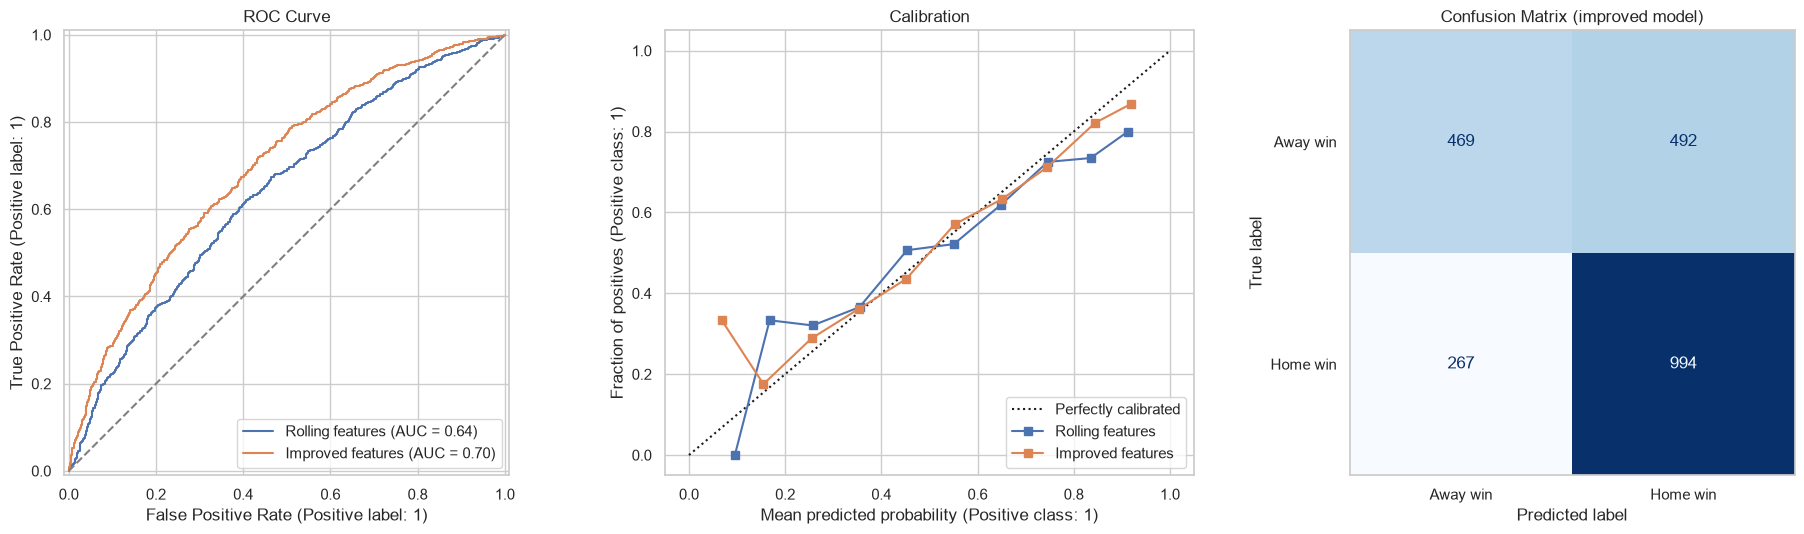

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

for name in ("Rolling features", "Improved features"):
    RocCurveDisplay.from_predictions(y_test, probs[name], name=name, ax=axes[0])
    CalibrationDisplay.from_predictions(y_test, probs[name], n_bins=10, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("ROC Curve")
axes[1].set_title("Calibration")

ConfusionMatrixDisplay.from_predictions(
    y_test, (probs["Improved features"] > 0.5).astype(int),
    display_labels=["Away win", "Home win"], cmap="Blues", colorbar=False, ax=axes[2],
)
axes[2].set_title("Confusion Matrix (improved model)")
axes[2].grid(False)

plt.tight_layout()
plt.show()

## Feature Interpretation

Coefficients of the improved model. The features are standardized, so magnitudes are comparable.

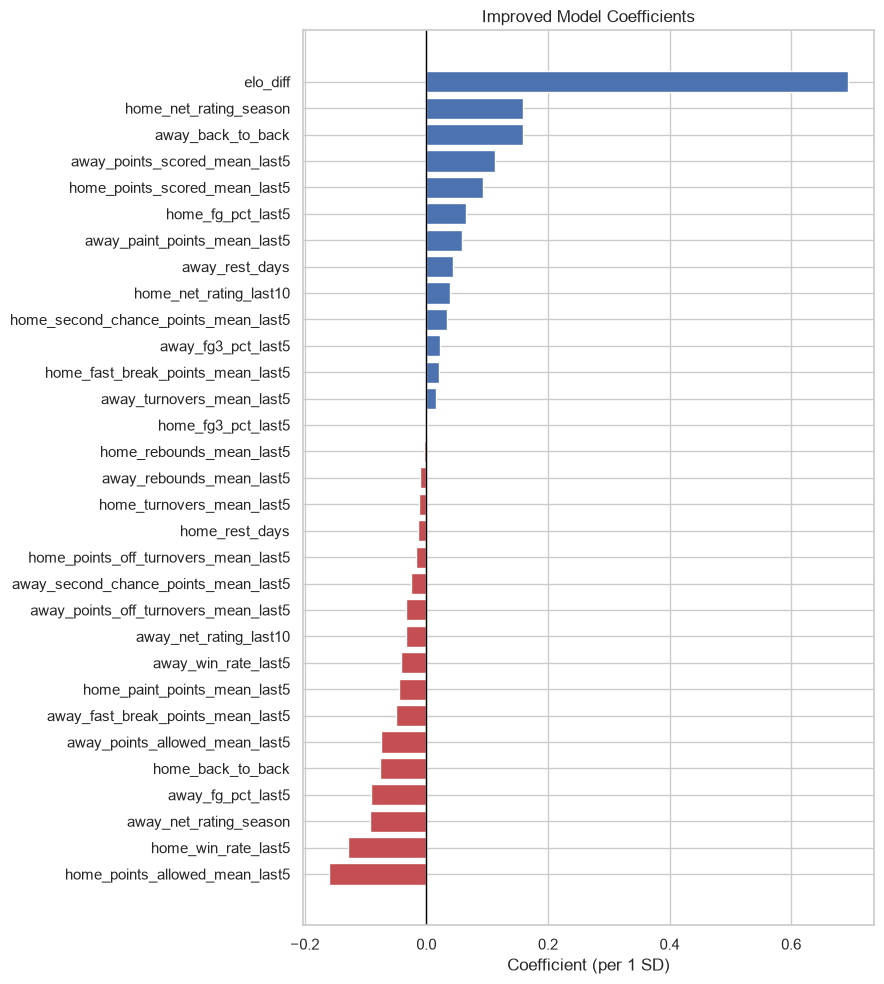

In [8]:
coefs = pd.DataFrame({"Feature": improved_cols, "Coefficient": model_improved.coef_[0]}).sort_values("Coefficient")

fig, ax = plt.subplots(figsize=(9, 10))
colors = ["#C44E52" if c < 0 else "#4C72B0" for c in coefs["Coefficient"]]
ax.barh(coefs["Feature"], coefs["Coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Improved Model Coefficients")
ax.set_xlabel("Coefficient (per 1 SD)")
plt.tight_layout()
plt.show()

## Next Steps
There are many steps we could take to improve accuracy of our model.

**Features**
- **Player availability**
- **Elo system refinement**
- **Opponent-adjusted rolling stats** 
- **Fewer, less overlapping features** 

**Models**
- **Point-margin regression:** predict `point_differential` with the same features
- **Tuning and nonlinear models:** tune the logistic regression's regularization, then try gradient boosting to catch interactions 

**Analysis and visualizations**
- **Accuracy by season and by month:** early-season games should be harder to predict.
- **Hit rate by confidence:** how often the model is right when it gives 55%, 65%, 75%+.
- **Elo over time**
- **Feature correlation heatmap**
- **Comparison with betting lines** 

In [9]:
results_path = data_dir / "home_win_model_results.csv"
pd.DataFrame(results).round(6).to_csv(results_path, index=False)
print(f"Saved model comparison to {results_path}")

Saved model comparison to ..\data\home_win_model_results.csv
